# Fraudes em entregas do Walmart (Flórida Central)

Projeto final do bootcamp de Data Science da Data Tech Florida, refeito em Python depois da entrega.

O Walmart recebe reclamações de itens que não chegam ao cliente. A base tem 10.000 pedidos de 2023 em 7 cidades da região de Orlando, a lista de entregadores, os produtos e os itens declarados como faltantes.

A pergunta do desafio era se a fraude vem dos motoristas, dos clientes ou de alguma falha do processo, e o que fazer para reduzir.

Na primeira versão eu comparei totais (região com mais itens faltando, entregador com mais itens faltando). Aqui eu comparo taxas e testo se a diferença é maior do que o acaso explicaria.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

DADOS = Path("..") / "dados"
IMAGENS = Path("..") / "imagens"

pedidos = pd.read_csv(DADOS / "pedidos.csv", parse_dates=["order_date"])
entregadores = pd.read_csv(DADOS / "entregadores.csv")
itens_perdidos = pd.read_csv(DADOS / "itens_perdidos.csv")
produtos = pd.read_csv(DADOS / "produtos.csv")

# cores dos gráficos: azul para o que importa, cinza para o resto
AZUL = "#2a78d6"
CINZA = "#c3c2b7"
TEXTO = "#52514e"
plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": TEXTO, "ytick.color": TEXTO, "axes.labelcolor": TEXTO,
    "legend.frameon": False, "savefig.dpi": 150, "savefig.bbox": "tight",
})

pedidos["perda"] = pedidos["items_missing"] > 0
pedidos.head()

,order_id,order_date,delivery_hour,region,driver_id,customer_id,items_delivered,items_missing,order_amount,perda
0,44dd6e53-7cf3-46cf-bd72-f011fefcd55a,2023-01-01,00:19:23,Kissimmee,WDID10385,WCID6233,4,0,212.37,False
1,9fe3cd7c-7240-4e24-93e8-2196a8076812,2023-01-01,00:52:37,Winter Park,WDID10719,WCID5693,11,0,326.35,False
2,bfc314f8-66f8-4abc-b884-f3950a9466c2,2023-01-01,01:13:36,Apopka,WDID09883,WCID5752,14,0,406.72,False
3,de3f8888-9975-4e00-9f0d-89689bc34981,2023-01-01,01:26:54,Clermont,WDID11067,WCID5078,14,0,27.55,False
4,c48d53f9-4fa8-4d6b-a906-01a4b5ef5d7b,2023-01-01,01:37:33,Kissimmee,WDID10164,WCID5817,1,0,380.69,False


## 1. Análise exploratória

### Problemas que encontrei nas tabelas

Os arquivos originais do desafio (orders.csv e a planilha com as outras tabelas) se perderam, então tirei os dados do modelo do meu dashboard no Power BI com o script `src/preparar_dados.py`. Nele também fiz as correções abaixo.

- A coluna de id do produto estava escrita `produc_id`. Renomeei para `product_id`.
- As categorias de produto estão trocadas (Pepsi aparece como Dairy, Ziploc como Bakery). Só Electronics está certa, então separei os produtos em Eletrônicos e Mercado.
- As tabelas de itens perdidos e de produtos foram importadas sem cabeçalho e a linha de títulos virou um registro. Removi.
- Preço e valor do pedido estavam como texto (`$463.28`). Converti para número.
- Há 18 nomes de entregador repetidos para pessoas diferentes (por exemplo, dois Timothy Brown). Por isso agrupo sempre pelo `driver_id`.

Na primeira versão eu disse que a coluna de valor do pedido estava vazia. Ela estava vazia na importação que fiz para o SQL, mas no arquivo original os valores existem.

In [2]:
# a quantidade de itens perdidos do pedido bate com a lista de produtos perdidos?
lista = itens_perdidos.set_index("order_id")[["product_id_1", "product_id_2", "product_id_3"]].notna().sum(axis=1)
qtd = pedidos.set_index("order_id").loc[lista.index, "items_missing"]
print("pedidos com perda:", pedidos["perda"].sum())
print("pedidos na lista de itens perdidos:", len(lista))
print("pedidos em que a quantidade não bate:", (qtd != lista).sum())

pedidos com perda: 1502
pedidos na lista de itens perdidos: 1501
pedidos em que a quantidade não bate: 6


Só 6 pedidos não batem (dizem 2 itens e listam 3 produtos). Deixei como está.

### Visão geral

In [3]:
# uma linha por produto perdido (cada pedido lista até 3)
perdidos = itens_perdidos.melt(id_vars="order_id", value_name="product_id").dropna(subset=["product_id"])
perdidos = perdidos.merge(produtos, on="product_id", how="left")
pedidos["valor_perdido"] = pedidos["order_id"].map(perdidos.groupby("order_id")["price"].sum()).fillna(0)

total_itens = pedidos["items_missing"].sum()
print("pedidos:", len(pedidos))
print("pedidos com item faltando:", pedidos["perda"].sum(), f"({pedidos['perda'].mean():.1%})")
print("itens faltando:", total_itens, f"({total_itens / (total_itens + pedidos['items_delivered'].sum()):.1%} dos itens enviados)")
print(f"valor perdido: US$ {perdidos['price'].sum():,.2f}")

pedidos: 10000
pedidos com item faltando: 1502 (15.0%)
itens faltando: 1657 (1.6% dos itens enviados)
valor perdido: US$ 149,372.61


Em 2023, 15% dos pedidos chegaram com pelo menos um item faltando. Isso dá 1.657 itens e quase US$ 150 mil.

## 2. Testando os possíveis padrões

Para cada fator calculo a porcentagem de pedidos com item faltando em cada grupo e faço um teste qui-quadrado. Com p-valor acima de 0,05, considero que a diferença entre os grupos pode ser acaso.

In [4]:
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
pedidos["dia_semana"] = pd.Categorical(pedidos["order_date"].dt.dayofweek.map(dict(enumerate(dias))), dias)
pedidos["mes"] = pedidos["order_date"].dt.month
hora = pd.to_datetime(pedidos["delivery_hour"], format="%H:%M:%S").dt.hour
pedidos["horario"] = pd.cut(hora, [-1, 5, 11, 17, 23], labels=["0h-5h", "6h-11h", "12h-17h", "18h-23h"])
pedidos["tamanho"] = pd.cut(pedidos["items_delivered"], [0, 9, 15, 100], labels=["1-9 itens", "10-15", "16+"])
qtd_pedidos_cliente = pedidos.groupby("customer_id")["order_id"].transform("count")
pedidos["cliente"] = np.where(qtd_pedidos_cliente > 5, "6+ pedidos", "até 5 pedidos")
pedidos["faixa_valor"] = pd.qcut(pedidos["order_amount"], 4, labels=["até $148", "$148-270", "$270-393", "acima de $393"])

fatores = {"region": "Região", "dia_semana": "Dia da semana", "mes": "Mês", "horario": "Horário",
           "tamanho": "Tamanho do pedido", "cliente": "Cliente", "faixa_valor": "Valor do pedido"}
resultado = []
for coluna, nome in fatores.items():
    tabela = pd.crosstab(pedidos[coluna], pedidos["perda"])
    p = stats.chi2_contingency(tabela)[1]
    taxa = pedidos.groupby(coluna, observed=True)["perda"].mean()
    resultado.append([nome, f"{taxa.min():.1%}", f"{taxa.max():.1%}", round(p, 3)])
resultado = pd.DataFrame(resultado, columns=["fator", "menor taxa", "maior taxa", "p-valor"]).set_index("fator")
resultado

,menor taxa,maior taxa,p-valor
fator,,,
Região,13.9%,16.2%,0.588
Dia da semana,13.8%,16.1%,0.326
Mês,13.4%,17.0%,0.375
Horário,14.5%,16.1%,0.362
Tamanho do pedido,14.6%,15.7%,0.446
Cliente,14.9%,16.1%,0.357
Valor do pedido,12.7%,20.2%,0.000


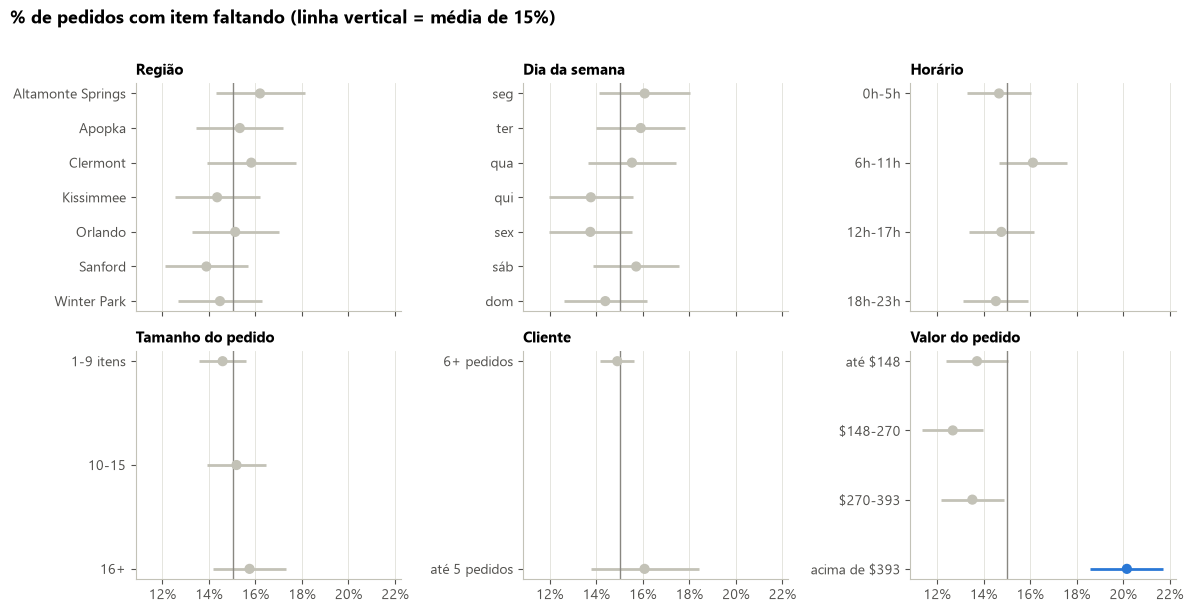

In [5]:
paineis = ["region", "dia_semana", "horario", "tamanho", "cliente", "faixa_valor"]
media = pedidos["perda"].mean()

fig, eixos = plt.subplots(2, 3, figsize=(12, 6.2), sharex=True)
for ax, coluna in zip(eixos.flat, paineis):
    g = pedidos.groupby(coluna, observed=True)["perda"].agg(["mean", "count"])
    erro = 1.96 * np.sqrt(g["mean"] * (1 - g["mean"]) / g["count"])  # intervalo de 95%
    significativo = resultado.loc[fatores[coluna], "p-valor"] < 0.05
    cores = [AZUL if significativo and m == g["mean"].max() else CINZA for m in g["mean"]]
    y = range(len(g))[::-1]
    ax.hlines(y, g["mean"] - erro, g["mean"] + erro, color=cores, lw=2)
    ax.scatter(g["mean"], y, color=cores, s=40, zorder=3)
    ax.axvline(media, color="#898781", lw=1)
    ax.set_yticks(list(y), g.index.astype(str))
    ax.grid(axis="y", visible=False)
    ax.set_title(fatores[coluna], fontsize=11)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.suptitle("% de pedidos com item faltando (linha vertical = média de 15%)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(IMAGENS / "01_taxa_por_fator.png")
plt.show()

Região, dia da semana, mês, horário, tamanho do pedido e cliente recorrente não mudam a taxa de forma significativa. Na primeira versão eu tinha apontado Altamonte Springs como a pior região e sexta e sábado como os piores dias, mas essas diferenças estão dentro do que o acaso produz.

O único fator que muda é o valor do pedido. Nos pedidos acima de US$ 393 a taxa é 20%, contra 13% a 14% nos outros.

## 3. Motoristas, clientes ou sistema?

### Entregadores

Se a perda fosse aleatória, ela ficaria espalhada entre quase todos os entregadores. Para ver como seria isso, embaralhei os itens perdidos entre os pedidos 1.000 vezes e contei quantos itens cada entregador teria.

In [6]:
por_entregador = pedidos.groupby("driver_id").agg(
    pedidos=("order_id", "count"),
    pedidos_com_perda=("perda", "sum"),
    itens_perdidos=("items_missing", "sum"),
    valor_perdido=("valor_perdido", "sum"),
).join(entregadores.set_index("driver_id"))
por_entregador["teve_perda"] = por_entregador["itens_perdidos"] > 0

rng = np.random.default_rng(42)
ids = pedidos["driver_id"].to_numpy()
itens = pedidos["items_missing"].to_numpy()
simulacoes = []
for _ in range(1000):
    soma = pd.Series(rng.permutation(itens)).groupby(ids).sum()
    simulacoes.append(soma.value_counts().reindex(range(13), fill_value=0))
esperado = pd.concat(simulacoes, axis=1).mean(axis=1)
observado = por_entregador["itens_perdidos"].value_counts().reindex(range(13), fill_value=0)

pd.DataFrame({"observado": observado, "esperado pelo acaso": esperado.round(0)}).head(10)

,observado,esperado pelo acaso
0,822,357.0
1,0,422.0
2,0,271.0
3,198,127.0
4,84,49.0
5,131,16.0
6,12,4.0
7,0,1.0
8,0,0.0
9,0,0.0


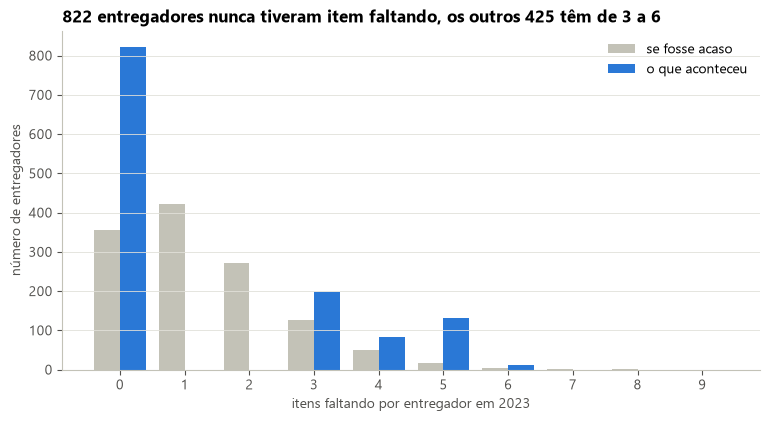

In [7]:
x = np.arange(10)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bar(x - 0.2, esperado[x], width=0.4, color=CINZA, label="se fosse acaso")
ax.bar(x + 0.2, observado[x], width=0.4, color=AZUL, label="o que aconteceu")
ax.set_xticks(x)
ax.set_xlabel("itens faltando por entregador em 2023")
ax.set_ylabel("número de entregadores")
ax.grid(axis="x", visible=False)
ax.legend()
ax.set_title("822 entregadores nunca tiveram item faltando, os outros 425 têm de 3 a 6")
fig.savefig(IMAGENS / "02_concentracao_entregadores.png")
plt.show()

In [8]:
por_entregador.groupby("teve_perda").agg(
    entregadores=("pedidos", "count"),
    pedidos_por_entregador=("pedidos", "mean"),
    pct_pedidos_com_perda=("pedidos_com_perda", "sum"),
    idade_media=("age", "mean"),
    valor_perdido=("valor_perdido", "sum"),
).assign(pct_pedidos_com_perda=lambda d: d["pct_pedidos_com_perda"] / por_entregador.groupby("teve_perda")["pedidos"].sum()).round(2)

,entregadores,pedidos_por_entregador,pct_pedidos_com_perda,idade_media,valor_perdido
teve_perda,,,,,
False,822,6.55,0.00,32.13,0.00
True,425,10.87,0.33,38.12,149372.61


Esse foi o resultado mais importante. Se fosse acaso, uns 360 entregadores ficariam sem nenhum item faltando e quase 700 teriam 1 ou 2. Nos dados, 822 entregadores (66%) nunca tiveram nenhum e ninguém tem 1 ou 2. Os outros 425 têm item faltando em cerca de um terço das entregas, e são eles que respondem por 100% da perda.

Um padrão tão limpo indica que a base provavelmente é sintética, mas a resposta para a pergunta do desafio fica clara: a perda está ligada a entregadores específicos.

### Idade dos entregadores

Na primeira versão concluí que os entregadores com mais problemas eram jovens de 18 anos. O que aconteceu foi que 12 entregadores de 18 anos empataram no topo do ranking com 6 itens, e a ordem entre eles era arbitrária. Comparando a proporção de cada faixa de idade que teve perda, o resultado é o oposto:

p-valor: 1.180587079704244e-11


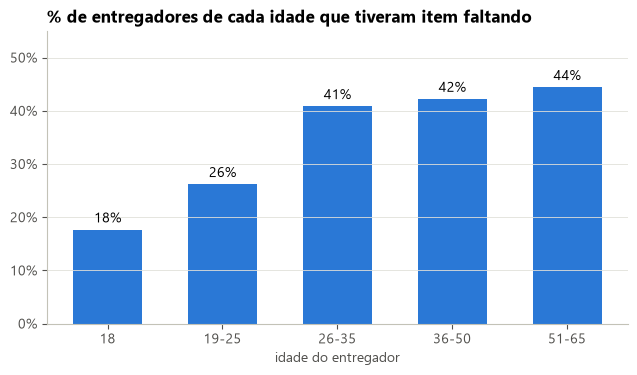

In [9]:
faixa_idade = pd.cut(por_entregador["age"], [17, 18, 25, 35, 50, 65], labels=["18", "19-25", "26-35", "36-50", "51-65"])
pct = por_entregador.groupby(faixa_idade, observed=True)["teve_perda"].mean()
print("p-valor:", stats.chi2_contingency(pd.crosstab(faixa_idade, por_entregador["teve_perda"]))[1])

fig, ax = plt.subplots(figsize=(7.5, 3.8))
barras = ax.bar(pct.index.astype(str), pct, color=AZUL, width=0.6)
ax.bar_label(barras, labels=[f"{v:.0%}" for v in pct], padding=3)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, 0.55)
ax.grid(axis="x", visible=False)
ax.set_xlabel("idade do entregador")
ax.set_title("% de entregadores de cada idade que tiveram item faltando")
fig.savefig(IMAGENS / "03_idade_entregador.png")
plt.show()

Só 18% dos entregadores de 18 anos tiveram item faltando, contra 44% dos que têm mais de 50.

### Clientes

Fiz o mesmo embaralhamento por cliente. Se alguns clientes estivessem declarando falta sem motivo, a perda se concentraria neles mais do que o acaso explica.

In [10]:
por_cliente = pedidos.groupby("customer_id")["items_missing"].sum()
clientes = pedidos["customer_id"].to_numpy()
variancias = [pd.Series(rng.permutation(itens)).groupby(clientes).sum().var() for _ in range(1000)]
p = np.mean(np.array(variancias) >= por_cliente.var())
print(f"variância observada: {por_cliente.var():.2f} | média no acaso: {np.mean(variancias):.2f} | p-valor: {p:.2f}")

variância observada: 1.60 | média no acaso: 1.61 | p-valor: 0.56


Não há concentração nos clientes (p-valor perto de 0,5). O Edward Henry, que era o cliente com mais itens faltando, recebeu vários pedidos de entregadores do grupo com perda.

## 4. Produtos

### Eletrônicos x mercado

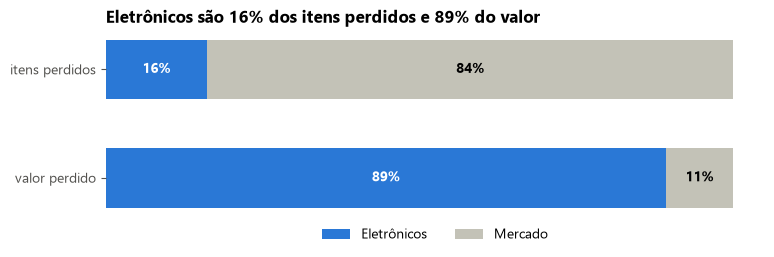

,itens,valor,% dos itens,% do valor
product_group,,,,
Eletrônicos,269,133398.60,0.162,0.893
Mercado,1393,15974.01,0.838,0.107


In [11]:
por_grupo = perdidos.groupby("product_group").agg(itens=("product_id", "count"), valor=("price", "sum"))
por_grupo["% dos itens"] = por_grupo["itens"] / por_grupo["itens"].sum()
por_grupo["% do valor"] = por_grupo["valor"] / por_grupo["valor"].sum()

fig, ax = plt.subplots(figsize=(8.5, 2.4))
for i, coluna in enumerate(["% do valor", "% dos itens"]):
    eletronicos = por_grupo.loc["Eletrônicos", coluna]
    ax.barh(i, eletronicos, color=AZUL, height=0.55, label="Eletrônicos" if i == 0 else None)
    ax.barh(i, 1 - eletronicos, left=eletronicos, color=CINZA, height=0.55, label="Mercado" if i == 0 else None)
    ax.text(eletronicos / 2, i, f"{eletronicos:.0%}", ha="center", va="center", color="white", fontweight="bold")
    ax.text(eletronicos + (1 - eletronicos) / 2, i, f"{1 - eletronicos:.0%}", ha="center", va="center", fontweight="bold")
ax.set_yticks([0, 1], ["valor perdido", "itens perdidos"])
ax.set_xticks([])
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2)
ax.set_title("Eletrônicos são 16% dos itens perdidos e 89% do valor")
fig.savefig(IMAGENS / "04_eletronicos_valor.png")
plt.show()
por_grupo.round(3)

In [12]:
# produtos que mais deram prejuízo
(perdidos.groupby("product_name")
 .agg(vezes=("product_id", "count"), preco=("price", "first"), valor_perdido=("price", "sum"))
 .sort_values("valor_perdido", ascending=False)
 .head(10))

,vezes,preco,valor_perdido
product_name,,,
Bose QuietComfort Earbuds,14,585.52,8197.28
Sony PlayStation 5,9,880.38,7923.42
Beats Studio Pro Headphone,11,690.88,7599.68
GoPro Hero 9,8,908.87,7270.96
Google Chromecast,9,750.72,6756.48
Roku Ultra Streaming Device,10,632.85,6328.50
Samsung Galaxy S21,8,783.07,6264.56
Nest Thermostat,11,528.96,5818.56
Nintendo Switch,8,725.50,5804.00


Itens de mercado somem com mais frequência, mas custam em média US$ 11. Um eletrônico perdido custa em média US$ 496, e os 10 produtos que mais deram prejuízo são todos eletrônicos.

Na primeira versão, a consulta de categorias usava um JOIN com OR e contou 1.357 itens de mercado. Com as três colunas de produto desempilhadas o total correto é 1.393 (ver `sql/consultas.sql`).

## 5. Recomendações e expectativa de redução

O desafio pedia uma expectativa de redução. Para estimar, simulei uma regra: depois que um entregador tem o primeiro pedido com item faltando, as entregas seguintes dele passam a exigir foto e assinatura do cliente. Percorri os pedidos em ordem de data e somei o prejuízo que aconteceu depois de o entregador já estar marcado. Esse é o máximo que a regra alcançaria.

In [13]:
ordem = pedidos.sort_values(["order_date", "delivery_hour"]).copy()
# quantos pedidos com perda o entregador já tinha antes deste
ordem["perdas_anteriores"] = ordem.groupby("driver_id")["perda"].cumsum() - ordem["perda"]
total = ordem["valor_perdido"].sum()

linhas = []
for k in [1, 2, 3]:
    marcado = ordem["perdas_anteriores"] >= k
    linhas.append([k, ordem.loc[marcado, "driver_id"].nunique(), f"{marcado.mean():.0%}",
                   f"{ordem.loc[marcado, 'valor_perdido'].sum():,.0f}",
                   f"{ordem.loc[marcado, 'valor_perdido'].sum() / total:.0%}"])
pd.DataFrame(linhas, columns=["marcar após k perdas", "entregadores marcados", "% dos pedidos com conferência",
                              "prejuízo alcançado (US$)", "% do prejuízo"]).set_index("marcar após k perdas")

,entregadores marcados,% dos pedidos com conferência,prejuízo alcançado (US$),% do prejuízo
marcar após k perdas,,,,
1,425,35%,"98,722",66%
2,425,24%,"61,278",41%
3,378,13%,"24,162",16%


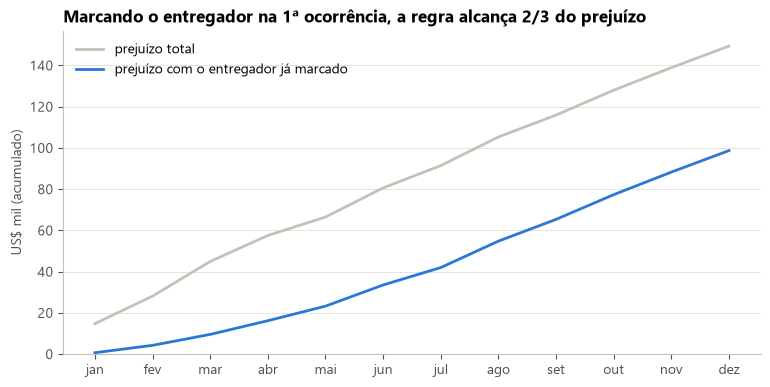

se a conferência evitar 25% das perdas: US$ 24,681 a menos (17% do prejuízo)
se a conferência evitar 50% das perdas: US$ 49,361 a menos (33% do prejuízo)
se a conferência evitar 75% das perdas: US$ 74,042 a menos (50% do prejuízo)


In [14]:
marcado = ordem["perdas_anteriores"] >= 1
mensal = (ordem.assign(mes=ordem["order_date"].dt.month, alcancado=np.where(marcado, ordem["valor_perdido"], 0))
          .groupby("mes")[["valor_perdido", "alcancado"]].sum().cumsum() / 1000)
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(mensal.index, mensal["valor_perdido"], color=CINZA, lw=2, label="prejuízo total")
ax.plot(mensal.index, mensal["alcancado"], color=AZUL, lw=2, label="prejuízo com o entregador já marcado")
ax.set_xticks(range(1, 13), meses)
ax.set_ylim(0)
ax.set_ylabel("US$ mil (acumulado)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("Marcando o entregador na 1ª ocorrência, a regra alcança 2/3 do prejuízo")
fig.savefig(IMAGENS / "05_regra_deteccao.png")
plt.show()

alcancado = ordem.loc[marcado, "valor_perdido"].sum()
for eficacia in [0.25, 0.5, 0.75]:
    print(f"se a conferência evitar {eficacia:.0%} das perdas: US$ {alcancado * eficacia:,.0f} a menos ({alcancado * eficacia / total:.0%} do prejuízo)")

Se a conferência evitar metade das perdas desses entregadores, o prejuízo cai cerca de um terço (uns US$ 50 mil por ano nesta amostra). A eficácia real só um teste A/B vai mostrar.

Nesta base não há falso positivo, porque quem nunca perdeu nada não tem nenhuma ocorrência. Com dados reais haveria ocorrências isoladas e legítimas, e talvez fosse melhor marcar só na segunda ocorrência, que ainda alcança 41% do prejuízo.

Recomendações:

1. Marcar o entregador na primeira ocorrência e exigir foto e assinatura nas entregas seguintes dele.
2. Exigir a mesma conferência em todo pedido com eletrônico ou acima de US$ 400, independente do entregador.
3. Testar as duas medidas com teste A/B antes de levar para todas as regiões.
4. Manter a comunicação com o cliente (aviso para conferir os itens na entrega), que já estava na primeira versão.

## 6. Dados que ajudariam

- GPS e tempo parado no endereço de entrega.
- Foto da entrega e confirmação do cliente na hora.
- Registro de conferência na saída do estoque, para separar erro de separação de desvio na entrega.
- Histórico de reclamações por canal (app, telefone, loja).

Também vale lembrar que a base parece sintética: os padrões são limpos demais e alguns preços não fazem sentido (iPhone 13 Pro a US$ 180, Dell XPS 13 a US$ 197).